# 11 · Write an energy-loss module in Python

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhputschke/js-contrib/blob/main/tutorials/pyjetscape/11_python_module.ipynb)

**Time:** 45 minutes · **Needs:** X-SCAPE (container, Mac wheel or source build) · **Data:** none: it runs X-SCAPE (about a minute, most of it LBT reading its tables)

Every stage of an X-SCAPE event can be a Python class: you subclass the C++ base class and
override the method X-SCAPE calls. This tutorial writes an energy-loss module, a simple model
of a quark that loses energy to a hot medium, and puts it to work:
- how X-SCAPE calls an energy-loss module, and what it does with the result;
- the model, first as plain Python, then as a module;
- a run in a **brick**, a static medium of fixed temperature, where every answer can be
  checked by hand;
- the module named in the XML, like X-SCAPE's own modules;
- a comparison with X-SCAPE's C++ modules LBT and Matter in the same brick;
- what a Python module costs, and the mistakes that are easy to make.

Reference page: [Writing modules in Python](https://jhputschke.github.io/js-contrib/python/modules/).

> **The outputs shown** were produced on an Apple Silicon Mac, in the environment the xscape wheel 0.2.0 is built in, with the hydro on the GPU through Metal.

In [1]:
# Setup: the tutorial helpers sit next to this notebook (_common/).
import os, sys
sys.path.insert(0, os.getcwd())
from _common import tutorial_env as te
env = te.setup()

tutorials v1.dev | setup: source (runs X-SCAPE; hydro: Metal GPU) | Python 3.13.1 | data: data/


In [2]:
ok, missing = te.meets(['xscape'], env.caps)
assert ok, f"this tutorial needs {missing}: see 01_check_setup.ipynb"

## 1. How X-SCAPE calls an energy-loss module

The hard process (here a parton gun) makes the partons that start the jets. For each one the
**energy-loss manager** makes a **shower**: it copies (`Clone()`) the modules named in
`<Eloss>`, and steps the shower through time, $t = 0, \Delta t, 2\Delta t, \dots$ up to
`<Eloss><maxT>`. At every step, every parton of the shower goes to every module, in their XML
order, through one call:

```python
DoEnergyLoss(self, deltaT, time, Q2, pIn, pOut)
```

- `deltaT` is the step [fm/c] and `time` the end of the step;
- `pIn[0]` is the parton, the C++ object itself, valid during the call only;
- `Q2` is the parton's $p_T$ (not a virtuality: that is `pIn[0].virtuality()`).

What the module returns decides what happens to the parton:

| returned | the shower |
|---|---|
| `None` (or nothing) | the parton goes on, unchanged |
| one parton | it replaces the parton; no new vertex |
| two or more | a **vertex** at `time`; each parton is a new line of the shower |

The shower is a graph: its lines are partons, its nodes vertices. The partons that end it
(the *final partons*) go on to hadronization. A module has more hooks (`InitTask()` once at
the start, `ClearTask()` after every event, `FinishTask()` at the end), but an energy-loss
module only needs `DoEnergyLoss`. The other stages work the same way, with their own base
class and method:

| stage | base class (`jetscape.pyjetscape_core`) | override |
|---|---|---|
| hard process | `HardProcess` | `ExecuteTask` |
| energy loss | `JetEnergyLoss` | `DoEnergyLoss` |
| jet hadronization | `Hadronization` | `DoHadronization` |
| soft particlization | `SoftParticlization` | `ExecuteTask` |
| hydro | `FluidDynamics` | `InitializeHydro`, `EvolveHydro` |
| writer | `JetScapeWriter` | `Write`, `WriteEvent` |

The C++ energy-loss modules of the build are in the same module factory your module will
join:

In [3]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
import jetscape as js
from jetscape import pyjetscape_core as core

registered = core.registered_modules()
print(len(registered), "modules registered, energy loss among them:",
      [m for m in registered if m in ("Matter", "Lbt", "Martini", "AdSCFT")])

38 modules registered, energy loss among them: ['AdSCFT', 'Lbt', 'Martini', 'Matter']


## 2. The model: a parton that collides with the plasma

A fast quark crossing a quark–gluon plasma collides with the plasma's quarks and gluons. Each
collision hands a small energy $\omega$ to a medium parton. A simple estimate of how this
depends on the temperature $T$:
- the density of scatterers grows as $T^3$;
- the cross section, screened at the Debye mass $m_D \sim gT$, falls as $1/T^2$;
- so the collision rate grows as $T$, and each collision takes an energy of order $T$.

The mean energy loss per unit length is therefore

$$\frac{dE}{dx} = \left(\frac{dE}{dx}\right)_\text{ref} \left(\frac{T}{T_\text{ref}}\right)^{2},$$

the temperature dependence of **collisional** energy loss. Radiative energy loss (gluon
bremsstrahlung, which LBT and Matter include) grows faster with $T$ and with the path length.

We make the loss **random**, as it is in nature: in a step of length $\Delta x$ the parton
receives $n$ kicks, $n$ Poisson-distributed with mean $(dE/dx)\,\Delta x/\langle\omega\rangle$,
and each kick takes an energy $\omega$ drawn from an exponential of mean
$\langle\omega\rangle = 3T$, about the mean energy of a thermal parton. The mean loss is then
exactly $dE/dx\cdot\Delta x$, and its spread over a path is
$\sigma_{\Delta E} = \sqrt{2\,\langle\Delta E\rangle\,\langle\omega\rangle}$ (each kick
contributes $\langle\omega^2\rangle = 2\langle\omega\rangle^2$).

The assumptions, stated once:
- the parton moves at the speed of light on a straight line: no deflection;
- no vacuum shower: no virtuality, no splitting;
- $dE/dx$ does not depend on the parton's energy (a full calculation has a logarithm of $E$);
- the energy lost leaves the jet for good (it is not followed in the medium);
- no loss below $T_c = 0.16$ GeV, and a parton keeps at least $3T$, a thermal energy.

We take $(dE/dx)_\text{ref} = 2$ GeV/fm at $T_\text{ref} = 0.3$ GeV: a round number of the order
of perturbative estimates for a light quark. It is a parameter of the model, read from the XML.

## 3. The module

The module is a file, `out/11_python_module/thermal_loss.py`, written by the next cell. The physics is the
function `kicks()`, which knows nothing about X-SCAPE; the class around it is what X-SCAPE
calls.

In [4]:
os.makedirs("out/11_python_module", exist_ok=True)

In [5]:
%%writefile out/11_python_module/thermal_loss.py
"""thermal_loss.py: a toy energy-loss module for X-SCAPE, written in Python.

A parton loses energy in random kicks from the medium.  On average
    dE/dx = dEdx_ref * (T / T_ref)**power        [GeV/fm],
and each kick takes an energy drawn from an exponential with mean omega_T * T.
The energy lost leaves the jet: it is written as a gluon of status -13, the status
X-SCAPE uses for energy handed to the medium, which does not propagate further.
"""
import jetscape as js
from jetscape import pyjetscape_core as core

MISSING = -13          # X-SCAPE's status for energy lost to the medium (as AdSCFT uses)


def kicks(rng, T, length, dEdx_ref=2.0, T_ref=0.3, power=2.0, omega_T=3.0):
    """The energy [GeV] a parton loses over `length` [fm] at temperature T [GeV]."""
    omega = omega_T * T                                    # mean energy of one kick
    mean_loss = dEdx_ref * (T / T_ref) ** power * length   # what dE/dx gives on average
    n = rng.poisson(mean_loss / omega)                     # the number of kicks
    return rng.exponential(omega, size=n).sum()


@js.module("CustomModuleThermalLoss", section="Eloss")
class ThermalLoss(core.JetEnergyLoss):
    """Energy loss in thermal kicks, dE/dx = dEdx_ref (T/T_ref)^power, above T_c."""

    xml_parameters = {"dEdx_ref": 2.0, "T_ref": 0.3, "power": 2.0, "omega_T": 3.0,
                      "T_c": 0.16, "vertex": True}
    trace = None       # a list here records (time, T, E after the step) of every call

    def DoEnergyLoss(self, deltaT, time, Q2, pIn, pOut):
        p = pIn[0]
        E, px, py, pz = p.momentum
        t0, x0, y0, z0 = p.position                # where the parton was made
        s = time - t0                              # it moves on a straight line, v = p/E
        here = (time, x0 + s * px / E, y0 + s * py / E, z0 + s * pz / E)
        cell = self.GetHydroCell(*here)            # the medium at the parton (None: none)
        T = cell.temperature if cell is not None else 0.0

        dE = 0.0
        if T >= self.T_c and p.pstat() >= 0:       # leave holes (status < 0) alone
            dE = kicks(self.rng, T, deltaT, self.dEdx_ref, self.T_ref, self.power,
                       self.omega_T)
            dE = min(dE, E - 3 * T)                # a parton keeps at least ~3T
        if self.trace is not None:
            self.trace.append((time, T, E - max(dE, 0.0)))
        if dE <= 0:
            return None                            # unchanged: it streams on

        f = (E - dE) / E                           # keep the direction, scale (E, p)
        if not self.vertex:                        # the wrong way (section 7)
            p.reset_momentum(px * f, py * f, pz * f, E * f)
            return None
        out = js.make_parton(p.pid(), (E * f, px * f, py * f, pz * f), here,
                             stat=p.pstat(), label=p.plabel(), color=p.color(),
                             anti_color=p.anti_color())
        lost = js.make_parton(21, (dE, px * (1 - f), py * (1 - f), pz * (1 - f)), here,
                              stat=MISSING)
        return [out, lost]                         # two partons: a vertex at `time`


Overwriting out/11_python_module/thermal_loss.py


What the pieces do:

- **`@js.module("CustomModuleThermalLoss", section="Eloss")`** registers the class in X-SCAPE's
  module factory under that name, so an XML can name it (section 5). The name must contain
  `CustomModule`.
- **`xml_parameters`** are the module's parameters with their defaults. Before the module
  starts, each is read from the XML into an attribute: `self.dEdx_ref`, `self.power`, ...
- **`self.GetHydroCell(t, x, y, z)`** asks the medium for the fluid cell at the parton's
  position: temperature, energy density, flow velocity.
- **`self.rng`** is a numpy random generator seeded from the module's own C++ random engine: the
  run is reproducible with `<Random><seed>`, and each shower's copy of the module has its own
  stream. Never use `np.random` without a seed, or Python's `random`, in a module.
- **The return value.** A parton that loses energy is returned *together with* the energy it
  lost, as a gluon of status −13. Two partons make a vertex, and only at a vertex does the
  shower write a parton down. Section 7 shows what happens with one parton.
- `vertex` and `trace` are there for this tutorial: `trace` records every call, and
  `vertex = False` switches to the wrong way of changing a parton.

### Test the physics before X-SCAPE

`kicks()` is plain Python, so we can check it in isolation: the loss over 1 fm at three
temperatures, 20,000 times each, against the mean and spread from section 2.

   T   mean dE (expected)   spread (expected)   kicks per fm
  0.2   0.900 (0.889)        1.041 (1.033)        1.48
  0.3   1.998 (2.000)        1.886 (1.897)        2.22
  0.4   3.545 (3.556)        2.906 (2.921)        2.96


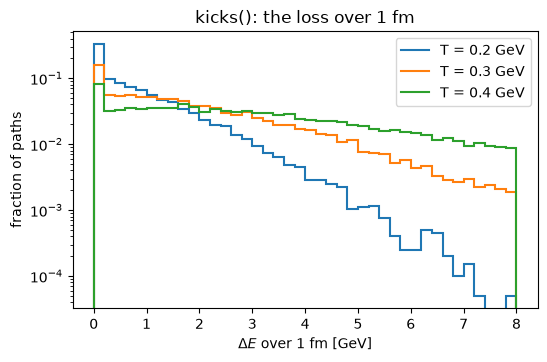

In [6]:
sys.path.insert(0, os.path.abspath("out/11_python_module"))
import thermal_loss as tl
import hist
import mplhep as mh

rng = np.random.default_rng(1)
h = hist.Hist(hist.axis.StrCategory([], growth=True, name="T"),
              hist.axis.Regular(40, 0, 8, name="dE", label=r"$\Delta E$ over 1 fm [GeV]"))
print("   T   mean dE (expected)   spread (expected)   kicks per fm")
for T in (0.2, 0.3, 0.4):
    dE = np.array([tl.kicks(rng, T, 1.0) for _ in range(20000)])
    mean_exp = 2.0 * (T / 0.3) ** 2
    print(f"  {T:.1f}   {dE.mean():5.3f} ({mean_exp:5.3f})        {dE.std():5.3f} ({np.sqrt(2 * mean_exp * 3 * T):5.3f})"
          f"        {mean_exp / (3 * T):4.2f}")
    h.fill(T=f"T = {T} GeV", dE=dE)

fig, ax = plt.subplots(figsize=(6, 3.6))
for name in h.axes["T"]:
    mh.histplot(h[name, :] / h[name, :].sum(), ax=ax, label=name, flow="none")
ax.set(ylabel="fraction of paths", yscale="log", title="kicks(): the loss over 1 fm")
ax.legend();

**What to notice.** The means follow $dE/dx \propto T^2$ and the spreads
$\sqrt{2\langle\Delta E\rangle\langle\omega\rangle}$, to within the statistical precision of
20,000 paths. The first bin stands out: at $T = 0.2$ GeV a parton gets about 1.5 kicks per fm,
so about a quarter of the paths ($e^{-1.5} \approx 0.23$) get no kick at all in 1 fm, and the
first bin (0–0.2 GeV) also holds the paths with only small kicks. The hotter the medium, the
more kicks and the narrower the distribution relative to its mean.

## 4. A run in a brick, built by hand

A **brick** is X-SCAPE's test medium (the C++ module `Brick`): a static, uniform plasma of
temperature $T$, at rest, until a time set by `<Eloss><Matter><brick_length>` (default
5 fm/c), and empty after. The parton gun `PGun` fires one quark (`parID` 1, a d quark) with
$p_T = 100$ GeV along $x$ from the origin at $t = 0$. The quark moves at the speed of light,
so after a time $t$ it has crossed a path $L = t$ of plasma: the brick turns *time* into
*path length*.

We build the pipeline in Python, as `run_by_hand.py` of the examples does: the gun, the brick,
and the energy-loss manager with a container holding our module. The user XML switches X-SCAPE's
own task list off and sets the run: 1000 events, the gun, the brick at $T = 0.3$ GeV, time
steps of 0.1 fm/c up to 5 fm/c. (X-SCAPE steps while $t <$ `maxT`, and $t$ collects
rounding errors: ten steps of 0.1 add up to slightly less than 1. A `maxT` half a step below
the end gives exactly 50 steps.)

X-SCAPE's C++ code prints its messages to the process's standard output and error. In Jupyter they
would fill the notebook, so `xscape_log()` sends them to a file while X-SCAPE runs.

In [7]:
import ctypes
from contextlib import contextmanager

@contextmanager
def xscape_log(path):
    """Send what C++ code prints (to file descriptors 1 and 2) to the file `path`."""
    libc = ctypes.CDLL(None)
    sys.stdout.flush(); sys.stderr.flush(); libc.fflush(None)
    saved = [os.dup(1), os.dup(2)]
    with open(path, "w") as f:
        os.dup2(f.fileno(), 1)
        os.dup2(f.fileno(), 2)
        try:
            yield
        finally:
            libc.fflush(None)
            for fd, copy in zip((1, 2), saved):
                os.dup2(copy, fd)
                os.close(copy)

In [8]:
from pathlib import Path

Path("out/11_python_module/brick_by_hand.xml").write_text("""<?xml version="1.0"?>
<jetscape>
  <nEvents>1000</nEvents>
  <vlevel>0</vlevel>
  <Random><seed>1</seed></Random>
  <enableAutomaticTaskListDetermination> false </enableAutomaticTaskListDetermination>
  <Hard><PGun><name>PGun</name><pT>100</pT><parID>1</parID></PGun></Hard>
  <Hydro>
    <Brick bjorken_expansion_on="false" start_time="0.0">
      <name>Brick</name><T>0.3</T><v_x>0</v_x><v_y>0</v_y><v_z>0</v_z>
    </Brick>
  </Hydro>
  <Eloss><deltaT>0.1</deltaT><tStart>0.0</tStart><maxT>4.95</maxT></Eloss>
</jetscape>
""")

gun, brick = core.create_module("PGun"), core.create_module("Brick")   # C++ modules
eloss_manager = core.JetEnergyLossManager()     # copies `eloss` once per shower
eloss = core.JetEnergyLoss()                    # the shower: steps it in time
eloss.Add(tl.ThermalLoss())                     # our module inside
eloss_manager.Add(eloss)

tl.ThermalLoss.trace = []                       # record every call (one list for all copies)
E_lead, E_lost, n_vertex = [], [], []
t0 = time.time()
with xscape_log("out/11_python_module/brick_by_hand.log"), js.JobDir("out/11_python_module", "out/11_python_module/brick_by_hand.xml") as job:
    with js.per_event(job.main_xml, job.user_xml, tasks=[gun, brick, eloss_manager]) as driver:
        print("tasks:", [type(t).__name__ for t in driver.GetTaskList()])
        t1 = time.time()
        for i in driver.events():
            fp = driver.energy_loss_manager.final_parton_array()     # numpy records
            E_lead.append(fp["E"][fp["pstat"] >= 0].max())
            E_lost.append(fp["E"][fp["pstat"] == tl.MISSING].sum())
            n_vertex.append(np.count_nonzero(fp["pstat"] == tl.MISSING))   # steps with a kick
        t_loop = time.time() - t1
E_lead, E_lost, n_vertex = map(np.array, (E_lead, E_lost, n_vertex))
E0 = np.sqrt(100.0**2 + 0.33**2)                # the gun's d quark: pT = 100 GeV, mass 0.33 GeV
trace = np.array(tl.ThermalLoss.trace).reshape(len(E_lead), -1, 3)    # event, step, (t, T, E)
tl.ThermalLoss.trace = None
print(f"{len(E_lead)} events in {t_loop:.2f} s; {trace.shape[1]} calls per event")
print(f"leading parton: {E_lead.mean():.2f} GeV on average; lost: {E_lost.mean():.2f} GeV"
      f" in {n_vertex.mean():.1f} of the {trace.shape[1]} steps; sum {np.mean(E_lead + E_lost):.4f} GeV")

tasks: ['HardProcess', 'FluidDynamics', 'JetEnergyLossManager']


1000 events in 0.43 s; 50 calls per event
leading parton: 89.88 GeV on average; lost: 10.12 GeV in 10.0 of the 50 steps; sum 100.0005 GeV


On average the quark lost 10.1 GeV in 5 fm, as $dE/dx = 2$ GeV/fm predicts. The kicks fell
in 10 of the 50 steps (a step can hold more than one kick, about 11 in all). The quark's energy
plus what it lost is the gun's energy: the energy is all accounted for. It is 100.0005 GeV
rather than 100 because `PGun` gives the d quark its mass (0.33 GeV), so
$E = \sqrt{p_T^2 + m^2}$.

The trace holds the quark's energy after every step, so one run gives the whole path-length
dependence:

mean loss at L = 5 fm from the trace: 10.123 GeV; from the final partons: 10.123 GeV


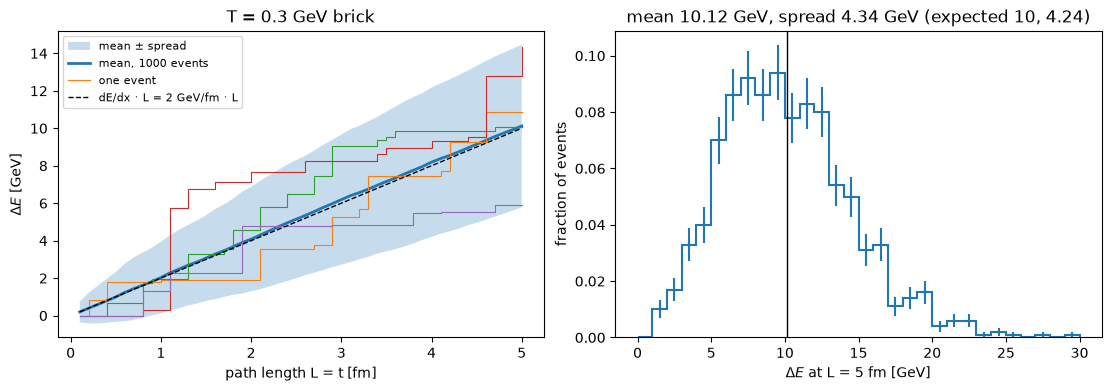

In [9]:
t = trace[0, :, 0]                       # the same times in every event
E_t = trace[:, :, 2]
dE_t = E0 - E_t                               # the loss so far

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
m, s = dE_t.mean(0), dE_t.std(0)
ax[0].fill_between(t, (m - s), (m + s), alpha=0.25, label="mean ± spread")
ax[0].plot(t, m, lw=2, label="mean, 1000 events")
for k in range(4):
    ax[0].step(t, dE_t[k], where="post", lw=0.8, label="one event" if k == 0 else None)
ax[0].plot(t, 2.0 * t, "k--", lw=1, label="dE/dx · L = 2 GeV/fm · L")
ax[0].set(xlabel="path length L = t [fm]", ylabel=r"$\Delta E$ [GeV]", title="T = 0.3 GeV brick")
ax[0].legend(fontsize=8)

h_dE = hist.Hist(hist.axis.Regular(30, 0, 30, name="dE", label=r"$\Delta E$ at L = 5 fm [GeV]"))
h_dE.fill(dE_t[:, -1])
mh.histplot(h_dE / len(E_lead), ax=ax[1], flow="none", yerr=np.sqrt(h_dE.values()) / len(E_lead))
mean5, sd5 = dE_t[:, -1].mean(), dE_t[:, -1].std()
ax[1].axvline(mean5, color="k", lw=1)
ax[1].set(ylabel="fraction of events", title=f"mean {mean5:.2f} GeV, spread {sd5:.2f} GeV "
          f"(expected 10, {np.sqrt(2 * 10 * 0.9):.2f})")
print(f"mean loss at L = 5 fm from the trace: {mean5:.3f} GeV; from the final partons: {E0 - E_lead.mean():.3f} GeV")

**What to notice.**

- **The mean loss grows linearly with the path length**, on the line $2\,\text{GeV/fm}\times L$:
  in a uniform medium a constant $dE/dx$ adds up step by step.
- **Single events are staircases.** Each step up is a kick; between kicks the quark streams
  freely. Event-by-event fluctuations are large: the spread at $L = 5$ fm is about 40 % of the
  mean, close to the 4.2 GeV that $\sqrt{2\langle\Delta E\rangle\langle\omega\rangle}$ predicts.
  Two quarks crossing the same medium can lose very different energies.
- **The trace and the final partons agree.** What the module saw at each step and what X-SCAPE
  wrote into the shower are the same thing, because the module makes a vertex at every kick.

## 5. Name the module in the XML

The run above built the pipeline by hand. X-SCAPE's usual way is to name the modules in the
user XML and let X-SCAPE build the pipeline (`<enableAutomaticTaskListDetermination>`, on by
default). Because `@js.module` registered the class, the user XML can name it in `<Eloss>`,
with its parameters inside, like any C++ module:

```xml
<Eloss>
  <deltaT>0.1</deltaT><maxT>5</maxT>
  <CustomModuleThermalLoss>
    <dEdx_ref>2.0</dEdx_ref>
    <power>2</power>
  </CustomModuleThermalLoss>
</Eloss>
```

Two rules make this work:
- **The name must contain `CustomModule`**: X-SCAPE creates no other name from the XML.
- **Every tag of the user XML needs a default in the main XML**, or X-SCAPE stops the process
  at `Init()`. Registering the module adds `<Eloss><CustomModuleThermalLoss>` with the
  `xml_parameters` as defaults to the main XML in memory (the file is not changed). Import the
  module file before `Init()`.

**One configuration per process.** X-SCAPE keeps the XML, the seed and the module registry in
process-wide singletons, so a second run with another XML in the same Python process is not
supported. We therefore run each configuration as its own script, `out/11_python_module/run_brick.py`, in a
new process. It writes the XML for one brick and one model, imports `thermal_loss.py` (which
registers the module), runs the events and saves, per event, the leading parton's energy and
the energy summed per parton status:

In [10]:
%%writefile out/11_python_module/run_brick.py
"""One brick run in its own process:   python run_brick.py MODEL L T N SEED [key=value ...]

A quark of pT = 100 GeV (PGun) crosses a static brick of temperature T [GeV] for L [fm].
MODEL: thermal (thermal_loss.py), lbt, matter_lbt, matter_vac.  key=value pairs set the
thermal module's XML parameters.  Writes brick/<name>.npz: per event the leading parton's
energy and the energy summed per status, and the run's timing."""
import os
import sys
import time

import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
import jetscape as js                  # noqa: E402
import thermal_loss                    # noqa: E402,F401  (registers CustomModuleThermalLoss)

LBT = "<Lbt><name>Lbt</name><Q0>2.0</Q0><in_vac>0</in_vac><alphas>0.2</alphas></Lbt>"
MODELS = {
    "thermal": "<CustomModuleThermalLoss>{params}</CustomModuleThermalLoss>",
    "lbt": LBT,
    "matter_lbt": "<Matter><in_vac>0</in_vac><brick_med>1</brick_med>"
                  "<brick_length>{L}</brick_length></Matter>" + LBT,
    "matter_vac": "<Matter><in_vac>1</in_vac></Matter>",
}
STATUSES = {"shower": 0, "recoil": 1, "hole": -1, "lost": -13}

XML = """<?xml version="1.0"?>
<jetscape>
  <nEvents>{N}</nEvents>
  <vlevel>0</vlevel>
  <Random><seed>{seed}</seed></Random>
  <Hard><PGun><name>PGun</name><pT>100</pT><parID>1</parID></PGun></Hard>
  <Hydro>
    <Brick bjorken_expansion_on="false" start_time="0.0">
      <name>Brick</name><T>{T}</T><v_x>0</v_x><v_y>0</v_y><v_z>0</v_z>
    </Brick>
  </Hydro>
  <Eloss>
    <deltaT>0.1</deltaT><tStart>0.0</tStart><maxT>{maxT}</maxT>
    {model}
  </Eloss>
</jetscape>
"""


def main(model, L, T, N, seed, *params):
    t_start = time.time()
    kv = dict(p.split("=", 1) for p in params)
    name = f"{model}_L{L:g}_T{T:g}" + "".join(f"_{k}{v}" for k, v in kv.items())
    out = os.path.join(HERE, "brick")
    os.makedirs(out, exist_ok=True)
    xml = os.path.join(out, name + ".xml")
    with open(xml, "w") as f:
        # X-SCAPE steps while t < maxT, and t collects rounding errors (10 x 0.1 < 1):
        # half a step below L gives exactly L / deltaT steps
        f.write(XML.format(N=N, seed=seed, T=T, maxT=L - 0.05, model=MODELS[model].format(
            L=L, params="".join(f"<{k}>{v}</{k}>" for k, v in kv.items()))))
    rows = []
    with js.JobDir(out, xml, name=name) as job:
        with js.per_event(job.main_xml, job.user_xml) as driver:
            t_init = time.time()
            for _ in driver.events():
                fp = driver.energy_loss_manager.final_parton_array()
                lead = fp["E"][fp["pstat"] >= 0].max()
                rows.append([lead, len(fp)] + [fp["E"][fp["pstat"] == s].sum()
                                               for s in STATUSES.values()])
            t_events = time.time()
    rows = np.array(rows)
    np.savez(os.path.join(out, name + ".npz"), E_lead=rows[:, 0], n_partons=rows[:, 1],
             init_s=t_init - t_start, events_s=t_events - t_init,
             **{f"E_{k}": rows[:, 2 + i] for i, k in enumerate(STATUSES)})


if __name__ == "__main__":
    main(sys.argv[1], float(sys.argv[2]), float(sys.argv[3]), int(sys.argv[4]),
         int(sys.argv[5]), *sys.argv[6:])


Overwriting out/11_python_module/run_brick.py


In [11]:
import subprocess

def run_brick(model, L, T, n=1000, seed=1, **params):
    """Run out/11_python_module/run_brick.py in a new process -> its results (a dict of arrays)."""
    name = f"{model}_L{L:g}_T{T:g}" + "".join(f"_{k}{v}" for k, v in params.items())
    cmd = [sys.executable, "out/11_python_module/run_brick.py", model, str(L), str(T), str(n), str(seed),
           *[f"{k}={v}" for k, v in params.items()]]
    r = subprocess.run(cmd, capture_output=True, text=True)
    Path(f"out/11_python_module/brick/{name}.log").write_text(r.stdout + r.stderr)    # X-SCAPE's output
    if r.returncode:
        raise RuntimeError(f"{name} failed, see out/11_python_module/brick/{name}.log")
    return dict(np.load(f"out/11_python_module/brick/{name}.npz"))

xml_run = run_brick("thermal", L=5, T=0.3)
print(Path("out/11_python_module/brick/thermal_L5_T0.3.xml").read_text())
print(f"named in the XML: E_lead = {xml_run['E_lead'].mean():.2f} ± {xml_run['E_lead'].std() / np.sqrt(1000):.2f} GeV"
      f" | by hand: {E_lead.mean():.2f} ± {E_lead.std() / np.sqrt(1000):.2f} GeV")
print("identical events:", np.array_equal(xml_run["E_lead"], E_lead))

<jetscape>
  <nEvents>1000</nEvents>
  <vlevel>0</vlevel>
  <Random><seed>1</seed></Random>
  <Hard><PGun><name>PGun</name><pT>100</pT><parID>1</parID></PGun></Hard>
  <Hydro>
    <Brick bjorken_expansion_on="false" start_time="0.0">
      <name>Brick</name><T>0.3</T><v_x>0</v_x><v_y>0</v_y><v_z>0</v_z>
    </Brick>
  </Hydro>
  <Eloss>
    <deltaT>0.1</deltaT><tStart>0.0</tStart><maxT>4.95</maxT>
    <CustomModuleThermalLoss />
  </Eloss>
</jetscape>
named in the XML: E_lead = 90.05 ± 0.14 GeV | by hand: 89.88 ± 0.14 GeV
identical events: False


The XML names only the gun, the brick and our module; everything else comes from the main
XML's defaults. The two runs agree within their statistical errors, but their events differ:
each module's random engine is seeded from the seed *and the module's task number*, and the
two pipelines number their tasks differently. With the same pipeline and the same seed, the
run is reproducible event by event (the check at the end relies on it).

## 6. Against LBT and Matter

X-SCAPE's standard jet energy loss uses two C++ modules:
- **LBT** (Linear Boltzmann Transport) follows the parton through the medium with elastic
  $2\to2$ collisions with thermal partons and medium-induced gluon radiation. It keeps the
  partons it knocks out of the medium (**recoils**, status 1) and the holes they leave behind
  (status −1, energy to be subtracted).
- **Matter** handles the parton while its virtuality is high, above $Q_0 = 2$ GeV: a
  vacuum-like shower modified by the medium. Below $Q_0$ it hands the partons to LBT. In
  the standard setup (Matter then LBT) a 100 GeV quark first showers in Matter, so its
  leading parton loses energy even in vacuum.

We compare the **energy loss of the leading parton**, $\Delta E = E_0 - E_\text{lead}$, the
highest-energy parton at the end, in the same brick:
- our module and LBT alone: $\Delta E$ itself (without a medium neither changes the quark);
- Matter + LBT: the difference to Matter in vacuum, $\langle E_\text{lead}\rangle_\text{vac} -
  \langle E_\text{lead}\rangle_\text{med}$, the part the medium adds.

The path length is set by `<maxT>` = $L$ (Matter also gets `<brick_length>` = $L$). Two scans,
each point one process with 1000 events: $L$ = 1–5 fm at $T = 0.3$ GeV, and $T$ = 0.2–0.4 GeV
at $L = 4$ fm. The runs are independent, so they run in parallel. LBT reads tables of about
0.6 GB when it starts, which takes 10–20 s per process and most of this cell's time.

In [12]:
from concurrent.futures import ThreadPoolExecutor

L_SCAN, T_SCAN = [1, 2, 3, 4, 5], [0.2, 0.25, 0.3, 0.35, 0.4]
jobs = [(m, L, 0.3) for m in ("matter_lbt", "lbt") for L in L_SCAN]
jobs += [("lbt", 4, T) for T in T_SCAN if T != 0.3]
jobs += [(m, L, 0.3) for m in ("matter_vac", "thermal") for L in L_SCAN]
jobs += [("thermal", 4, T) for T in T_SCAN if T != 0.3]

t0 = time.time()
workers = max(1, min(8, (os.cpu_count() or 2) // 2))
with ThreadPoolExecutor(workers) as pool:
    runs = dict(zip(jobs, pool.map(lambda j: run_brick(*j), jobs)))
print(f"{len(runs)} runs, {workers} at a time, in {time.time() - t0:.0f} s")

def loss(model, L, T):
    """<Delta E> of the leading parton and its statistical error."""
    e = runs[(model, L, T)]["E_lead"]
    if model == "matter_lbt":                     # the medium's part: vacuum minus medium
        v = runs[("matter_vac", L, T)]["E_lead"]
        return v.mean() - e.mean(), np.hypot(v.std(), e.std()) / np.sqrt(len(e))
    return E0 - e.mean(), e.std() / np.sqrt(len(e))

import pandas as pd
table = pd.DataFrame({(m, "dE"): [loss(m, L, 0.3)[0] for L in L_SCAN] for m in ("thermal", "lbt", "matter_lbt")},
                     index=pd.Index(L_SCAN, name="L [fm]"))
table.round(2)

28 runs, 8 at a time, in 42 s


,thermal,lbt,matter_lbt
,dE,dE,dE
L [fm],,,
1,2.00,1.58,1.01
2,3.94,4.52,1.56
3,6.02,7.28,3.37
4,8.00,10.38,6.60
5,9.95,13.13,8.78


<Delta E> at L = 4 fm [GeV]:
T [GeV]  0.20  0.25   0.30   0.35   0.40
thermal  3.52  5.53   8.00  10.97  14.30
lbt      4.75  7.47  10.38  11.80  15.25


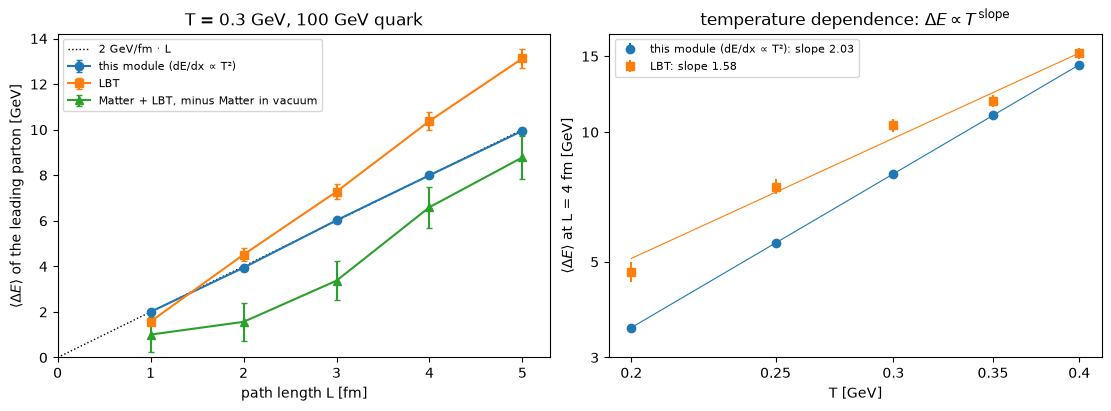

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
style = {"thermal": ("this module (dE/dx ∝ T²)", "o"), "lbt": ("LBT", "s"),
         "matter_lbt": ("Matter + LBT, minus Matter in vacuum", "^")}
for m, (label, mk) in style.items():
    y, e = np.array([loss(m, L, 0.3) for L in L_SCAN]).T
    ax[0].errorbar(L_SCAN, y, e, marker=mk, label=label, capsize=2)
ax[0].plot([0, 5], [0, 10], "k:", lw=1, label="2 GeV/fm · L")
ax[0].set(xlabel="path length L [fm]", ylabel=r"$\langle\Delta E\rangle$ of the leading parton [GeV]",
          title="T = 0.3 GeV, 100 GeV quark", xlim=(0, 5.3), ylim=(0, None))
ax[0].legend(fontsize=8)

slopes = {}
for m in ("thermal", "lbt"):
    y, e = np.array([loss(m, 4, T) for T in T_SCAN]).T
    slopes[m], c = np.polyfit(np.log(T_SCAN), np.log(y), 1, w=y / e)
    ax[1].errorbar(T_SCAN, y, e, marker=style[m][1], ls="none", label=f"{style[m][0]}: slope {slopes[m]:.2f}")
    ax[1].plot(T_SCAN, np.exp(c) * np.array(T_SCAN) ** slopes[m], lw=0.8, color=ax[1].lines[-1].get_color())
ax[1].set(xscale="log", yscale="log", xlabel="T [GeV]", ylabel=r"$\langle\Delta E\rangle$ at L = 4 fm [GeV]",
          title=r"temperature dependence: $\Delta E \propto T^{\,\mathrm{slope}}$")
ax[1].set_xticks(T_SCAN, [str(T) for T in T_SCAN]); ax[1].minorticks_off()
ax[1].set_yticks([3, 5, 10, 15], ["3", "5", "10", "15"])
ax[1].legend(fontsize=8)
print("<Delta E> at L = 4 fm [GeV]:")
print(pd.DataFrame({m: [loss(m, 4, T)[0] for T in T_SCAN] for m in ("thermal", "lbt")},
                   index=pd.Index(T_SCAN, name="T [GeV]")).round(2).T)

**What to notice.**

- **Our module is on its line** in $L$ and on $T^2$ in $T$, as it must be: the scans check the
  module, not the physics.
- **LBT starts slowly, then overtakes.** In the first fm its leading parton loses 1.6 GeV,
  less than our 2 GeV; after that it loses about 3 GeV per fm, and 13 GeV after 5 fm. Much of
  LBT's loss is gluon radiation, and a radiated gluon needs time to form: in the
  higher-twist formula LBT uses, the radiation rate grows with the time since the parton was
  produced. Our collisional model has no such delay.
- **LBT depends less steeply on $T$.** At $L = 4$ fm its loss grows from 4.8 to 15.3 GeV
  between $T$ = 0.2 and 0.4 GeV, a factor 3.2 where $T^2$ gives 4; the fit gives about
  $T^{1.6}$. The points scatter around the fitted line by somewhat more than their errors, so
  read the power as a summary of this range, not a law.
- **In Matter + LBT the medium takes less from the leading parton**: 1 GeV after 1 fm,
  9 GeV after 5 fm, below LBT alone at every $L$. The 100 GeV quark showers in Matter
  from the start, in a medium or not: in vacuum its leading parton has 82 GeV left after 1 fm
  and 73 GeV after 5 fm. The medium then acts on several softer partons instead of one hard
  quark. The errors are larger because the difference of two broad distributions is taken.

Where did the leading parton's energy go? The energy summed per status, at $L = 4$ fm and
$T = 0.3$ GeV (holes count negative):

In [14]:
rows = []
for m, label in [("thermal", "this module"), ("lbt", "LBT"), ("matter_lbt", "Matter + LBT"), ("matter_vac", "Matter, vacuum")]:
    r = runs[(m, 4, 0.3)]
    rows.append({"model": label, "leading parton": r["E_lead"].mean(),
                 "other shower partons": r["E_shower"].mean() - r["E_lead"].mean(),
                 "recoils": r["E_recoil"].mean(), "holes": -r["E_hole"].mean(),
                 "lost (status -13)": r["E_lost"].mean(), "partons": r["n_partons"].mean()})
book = pd.DataFrame(rows).set_index("model")
book["sum"] = book[["leading parton", "other shower partons", "recoils", "holes", "lost (status -13)"]].sum(axis=1)
book.round(2)

,leading parton,other shower partons,recoils,holes,lost (status -13),partons,sum
model,,,,,,,
this module,92.00,0.00,0.00,-0.00,8.0,8.95,100.00
LBT,89.62,4.11,14.50,-8.24,0.0,22.84,100.00
Matter + LBT,68.34,28.87,25.37,-22.56,0.0,62.04,100.02
"Matter, vacuum",74.94,25.06,0.00,-0.00,0.0,4.08,100.00


**What to notice.**

- **Every model conserves energy:** the columns add up to the gun's 100 GeV (Matter + LBT to
  within 0.02 GeV).
- **Our module** puts the 8 GeV the quark lost into status −13 gluons, about 8 per event (one
  per step with a kick): energy that left the jet.
- **LBT** takes 10.4 GeV from the leading parton. 4.1 GeV are in radiated gluons, which stay
  part of the jet. The rest went into the medium: LBT knocked medium partons out of the plasma
  (**recoils**, 14.5 GeV) and keeps the thermal partons they came from as **holes** (8.2 GeV,
  to subtract), a net 6.3 GeV. A jet in LBT carries its own medium response along.
- **Matter + LBT** turns the quark into a shower of about 60 partons, with recoils and holes of
  more than 20 GeV each.

So "energy loss" depends on what one counts: the leading parton, the shower partons, or the
shower with its medium response. Our module only has the first.

## 7. Cost and pitfalls

### Cost

Each call into a Python energy-loss module costs about 1.4 µs for the crossing from C++ to
Python, plus what its Python code costs. The runs above measured their own time:

In [15]:
calls = len(E_lead) * trace.shape[1]
print(f"this module, by hand: {calls} calls in {t_loop:.2f} s = {1e6 * t_loop / calls:.0f} µs per call (incl. the event loop)")
cost = pd.DataFrame([{"model": m, "start (s)": float(runs[(m, 4, 0.3)]["init_s"]),
                      "1000 events (s)": float(runs[(m, 4, 0.3)]["events_s"])}
                     for m in ("thermal", "lbt", "matter_lbt", "matter_vac")]).set_index("model")
cost.round(2)

this module, by hand: 50000 calls in 0.43 s = 9 µs per call (incl. the event loop)


,start (s),1000 events (s)
model,,
thermal,0.01,0.41
lbt,15.06,1.67
matter_lbt,13.66,9.68
matter_vac,0.01,2.27


Our module needs about 9 µs per call here, including X-SCAPE's own work per step and the
event loop in Python: 0.5 s for 1000 events of 50 steps. In the scan, 1000 events took about
half a second with our module, 2 s with LBT and 10 s with Matter + LBT, while each LBT process spent
13–18 s at its start, reading tables (eight processes started at once). For this brick the
Python module is the cheapest of all, because its physics is a few lines. A module that does
heavy work per parton and step in Python pays for every line; put such work into numpy
operations, or into C++.

### Pitfalls

**A changed parton needs a vertex.** The shower writes a parton down when a vertex makes it.
A module that changes the parton in place, or returns a single parton, changes what the next
step sees, but the shower keeps the parton as it was written. Our module's `vertex = False`
does exactly that (it calls `p.reset_momentum(...)` and returns `None`). Compare the same
brick both ways:

In [16]:
wrong = run_brick("thermal", L=5, T=0.3, vertex=0)
print(f"vertex = 1: leading parton {xml_run['E_lead'].mean():.2f} GeV, lost {xml_run['E_lost'].mean():.2f} GeV")
print(f"vertex = 0: leading parton {wrong['E_lead'].mean():.2f} GeV, lost {wrong['E_lost'].mean():.2f} GeV")

vertex = 1: leading parton 90.05 GeV, lost 9.95 GeV
vertex = 0: leading parton 99.79 GeV, lost 0.00 GeV


With `vertex = 0` the module takes the same energy from the quark, step by step, but the final
partons keep 99.8 GeV and nothing is marked as lost. The shower wrote the quark's line once,
after its first step (0.2 GeV lost on average), and never again. The output looks like a run
without a medium.

| symptom | cause |
|---|---|
| the module runs (its trace shows the loss) but the final partons do not change | the parton was changed without a vertex: return two partons |
| `User XML tag <X> is unrecognized` and the process stops | the module or one of its parameters is not registered before `Init()`: import the module file first |
| a module named in the XML never runs | its name does not contain `CustomModule` |
| the second run in a notebook behaves strangely | one configuration per process: run it as a script |
| results change when you add a module | the random streams follow the task numbers; adding a module shifts those of the tasks made after it |
| state shared between showers | `Clone()` copies attributes shallowly (our `trace` list is shared on purpose); override `Clone` for per-shower state |
| a parton's `t()` is not its virtuality | `t()` is the position's time; use `virtuality()` |
| slow runs | every call crosses into Python (about 1.4 µs) and runs your Python code; Python modules run in one thread |

### Check your result

In [17]:
import json
exp = json.load(open("expected/11_python_module.json"))
# the energy is conserved in every event, exactly
np.testing.assert_allclose(E_lead + E_lost, E0, rtol=1e-9)
# the model: <Delta E> = 2 GeV/fm * 5 fm, within 4 statistical errors
assert abs(mean5 - 10.0) < 4 * sd5 / np.sqrt(len(E_lead))
# X-SCAPE runs: the same numbers here; other setups differ slightly (other random numbers)
np.testing.assert_allclose(mean5, exp["thermal_dE_L5"], atol=0.5)
np.testing.assert_allclose([loss("lbt", L, 0.3)[0] for L in L_SCAN], exp["lbt_dE_vs_L"], atol=1.5)
np.testing.assert_allclose(slopes["thermal"], 2.0, atol=0.15)
np.testing.assert_allclose(wrong["E_lead"].mean(), exp["no_vertex_E_lead"], atol=0.1)
print("All checks pass.")

All checks pass.


## Exercises

1. **Radiative-like loss.** Run the module with `power=3` (`run_brick("thermal", 4, T, power=3)`)
   for the five temperatures. Then make $dE/dx$ grow with the path length, as radiative loss
   does ($dE/dx \propto T^3 L$, so $\Delta E \propto L^2$): add a parameter to
   `xml_parameters` and use `time - t0` of the parton in `DoEnergyLoss`. Which version is
   closest to LBT in $L$ and in $T$?
2. **Tune the model.** Find the `dEdx_ref` that matches LBT at $L = 4$ fm and $T = 0.3$ GeV.
   With that value, how far off are you at $L = 1$ fm and at $T = 0.2$ GeV?
3. **An expanding brick.** Set `bjorken_expansion_on="true"` and `start_time="0.6"` on the
   `<Brick>`: then $T(t) = T_0\,(0.6/t)^{1/3}$. Work out $\langle\Delta E\rangle(L)$ for
   $dE/dx \propto T^2$ by hand, and check it with the module.
4. **After Matter.** Put the module after Matter in `<Eloss>` (a new model in
   `run_brick.py`: `<Matter>...</Matter><CustomModuleThermalLoss/>`). Matter's partons then
   lose energy in our module too, at every virtuality. Restrict the module to partons with
   `p.virtuality() < 4` GeV² (Matter's $Q_0^2$), as LBT does, and compare with Matter + LBT.

## Next steps

- Tutorial 12: a writer of your own, which sees every event while it runs.
- The full reference for modules in Python, all stages: [Writing modules in Python](https://jhputschke.github.io/js-contrib/python/modules/).
- The results of an event as arrays (final partons, showers, hadrons): [The Pythonic interface](https://jhputschke.github.io/js-contrib/python/pythonic/).
- Energy loss in X-SCAPE's physics (Matter, LBT, the liquefier): [The physics](https://jhputschke.github.io/js-contrib/about/physics/).